In [3]:
import os
import numpy as np 
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

os.chdir(r"E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets")

In [6]:
milk  = pd.read_csv('milk.csv', index_col = 0)       # anila and milk ingredients dataset
milk


,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,90.1,2.6,1.0,6.9,0.35
ORANGUTAN,88.5,1.4,3.5,6.0,0.24
MONKEY,88.4,2.2,2.7,6.4,0.18
DONKEY,90.3,1.7,1.4,6.2,0.40
HIPPO,90.4,0.6,4.5,4.4,0.10
CAMEL,87.7,3.5,3.4,4.8,0.71
BISON,86.9,4.8,1.7,5.7,0.90
BUFFALO,82.1,5.9,7.9,4.7,0.78
GUINEA PIG,81.9,7.4,7.2,2.7,0.85


In [7]:
scaler = StandardScaler().set_output(transform='pandas')
scl_milk = scaler.fit_transform(milk)
scl_milk

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,0.948806,-1.009291,-0.903208,1.542217,-1.037554
ORANGUTAN,0.821407,-1.344603,-0.660619,1.040773,-1.259945
MONKEY,0.813445,-1.121062,-0.738247,1.263637,-1.381249
DONKEY,0.964731,-1.260775,-0.864394,1.152205,-0.936467
HIPPO,0.972694,-1.568145,-0.563583,0.149319,-1.542988
CAMEL,0.757707,-0.757806,-0.670322,0.372182,-0.309730
BISON,0.694008,-0.394551,-0.835283,0.873626,0.074400
BUFFALO,0.311810,-0.087181,-0.233662,0.316466,-0.168208
GUINEA PIG,0.295885,0.331959,-0.301587,-0.797852,-0.026687


In [9]:
prcomp = PCA().set_output(transform='pandas')
pca_data = prcomp.fit_transform(scl_milk)
pca_data

,pca0,pca1,pca2,pca3,pca4
Animal,,,,,
HORSE,2.435175,-0.231478,0.330150,0.307664,0.048184
ORANGUTAN,2.258736,-0.693148,0.029035,-0.081057,-0.000532
MONKEY,2.335861,-0.663328,0.101257,0.247997,0.010109
DONKEY,2.318677,-0.273815,0.109881,-0.092873,-0.006769
HIPPO,2.060294,-1.019199,-0.762436,-0.510091,0.029382
CAMEL,1.301536,0.137303,-0.198742,-0.282160,-0.014668
BISON,1.282742,0.622667,0.253785,0.065148,-0.044486
BUFFALO,0.505068,0.088235,0.008383,0.133774,0.083806
GUINEA PIG,-0.255502,0.287373,-0.881857,-0.013100,-0.016484


In [13]:
print(f'''
pcadata shape: {pca_data.shape}
milk data shape: {milk.shape}
''')


pcadata shape: (25, 5)
milk data shape: (25, 5)



In [14]:
pca_data.shape, milk.shape

((25, 5), (25, 5))

In [21]:
 pca_data.var()

pca0    4.040412
pca1    0.924372
pca2    0.134291
pca3    0.102689
pca4    0.006570
dtype: float64

In [20]:
sigma = scl_milk.cov()
values , vectors = np.linalg.eig(sigma)
print('Eigen values: ',values)

Eigen values:  [4.0404117  0.92437238 0.00656977 0.13429088 0.1026886 ]


In [25]:
prcomp.explained_variance_

array([4.0404117 , 0.92437238, 0.13429088, 0.1026886 , 0.00656977])

In [22]:
total_variation = pca_data.var().sum()
total_variation

np.float64(5.208333333333337)

In [ ]:
# total var = sumation(var(PC i))


In [23]:
# proportion of variation explained by pc

In [24]:
pca_data.var() / total_variation

pca0    0.775759
pca1    0.177479
pca2    0.025784
pca3    0.019716
pca4    0.001261
dtype: float64

In [26]:
prcomp.explained_variance_ratio_

array([0.77575905, 0.1774795 , 0.02578385, 0.01971621, 0.0012614 ])

In [34]:
prcomp.explained_variance_ratio_*100

array([77.57590469, 17.74794969,  2.57838496,  1.97162103,  0.12613963])

In [35]:
np.cumsum(prcomp.explained_variance_ratio_*100)

array([ 77.57590469,  95.32385438,  97.90223934,  99.87386037,
       100.        ])

In [36]:
pca_data[['pca1','pca1']]

,pca1,pca1
Animal,,
HORSE,-0.231478,-0.231478
ORANGUTAN,-0.693148,-0.693148
MONKEY,-0.663328,-0.663328
DONKEY,-0.273815,-0.273815
HIPPO,-1.019199,-1.019199
CAMEL,0.137303,0.137303
BISON,0.622667,0.622667
BUFFALO,0.088235,0.088235
GUINEA PIG,0.287373,0.287373


<Axes: xlabel='pca0', ylabel='pca0'>

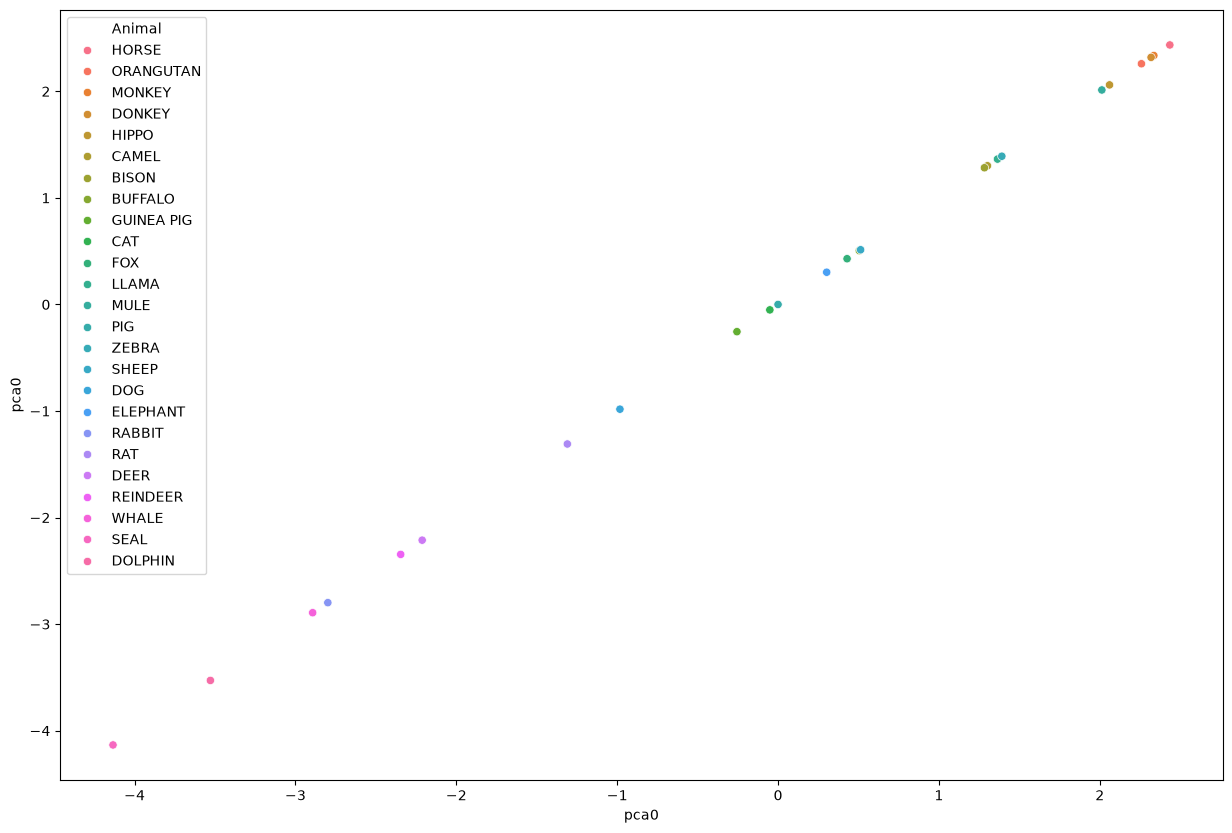

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15,10))
sns.scatterplot(x = pca_data['pca0'],y=pca_data['pca0'] , hue=pca_data.index)